## 古典的手法による白血球の検出

In [ ]:
# 手順
## notebookを参考に色味とサイズ感から白血球位置を取得

## これをBBOXとするような学習データの作成                                                                             
### 必要枚数については要調査
 ### 描画パッチのサイズをYOLO用に640×640にしておく必要がある
 #### クラスあたり1500枚/10000インスタンス                                                                                           
### データローダー側も整備する必要あり
 #### 画像とラベルをYOLOが読み込める形式(images/train, labels/trainのディレクトリ構成+クラス定義のyamlファイル)に整備する作業 

### あくまでアイデアレベルですがここでAugmentation挟めば染色ムラに頑健かつデータの拡張になる？
 #### Augmentation：データ拡張。1枚の画像に色味の変更・回転・斑点・拡大縮小などで水増しした別の学習サンプルを作って様々な見え方を人工的に増やして学習させる方法                                                                                 
 #### 効果１：一枚の画像から複数の見え方を作れるので見かけ上の学習データ枚数が増える。向きや解像度への頑健性
 #### 効果２：染色ムラへの頑健性：古典的手法のような色の絶対値で判断する場合は少しの染色変化で判定がブレるが，
 #### …YOLOに学習させる際は学習データの色味に多様性(色相・彩度・明度(HSV))を持たせることで染色ムラやパッチ差に強くできる
  #### YOLOは学習スクリプトに標準でAugmentation(HSVじったー，回転，斑点，拡大，縮小，mosaic合成など)が最初から組み込み済み
  #### 学習実行時のパラメータ(hsv_h, hsv_s, hsv_v, degrees, flipud, fliplr, scale など)として調整可能                   
                                                                                                                     
## 既存モデルの用意                                                                                                   
### Ultralytics YOLO11を使用                                                                               
                                                                                                                     
## ヘッドが白血球を認識できるようBBOX付きの画像で学習
 ## ヘッド：モデルの最終層(クラス分類・BBOX位置を出力する部分)。
 ## 事前学習済みモデルYOLO11は一般物体用(最終層が一般物体)に学習されているので，最終層が白血球クラスに対応するようBBOX月が増で再学習(転移学習・fine-tuningする)                                                                  
### ラベルを白血球だけにつける(最初は白血球の種類関係なく，WBC1クラスのみで学習する)                                                                                         
### 上手くいかなければ疑似BBOXを白血球と赤血球に拡張→セグメンテーション後のアノテーションが白血球の物だけをピックアップ？ 
 ### 赤血球なども検出してしまう場合，赤血球なども含めて疑似的にBBOXを付け(画像の分割に近い形で網羅的にラベル付け)，
 ### …確実に白血球と判断できるもののみ最終的な学習ラベルとして抽出するやり方。
 ### 他の血球なのに白血球として認識される「誤ラベル」を減らせる

## 実際の画像に適用
 ### 検出結果をさらに人手でレビュー・修正して学習データに戻せば反復的なアノテーション効率化(human-in-the-loop)になる
 #### human-in-the-loop-annotation：少量学習データでモデルを学習→テストデータでテスト
 #### →結果を人が確認・未認識の白血球は囲み，ズレた枠配置を直し，余計な枠は消す→学習データに追加→再学習のループ

In [1]:
from PIL import Image
import matplotlib.pyplot as plt 
import cv2
import numpy as np

from openslide import OpenSlide

from matplotlib.collections import LineCollection
# LineCollection…Matplotlibというグラフ描画ライブラリの機能。線を書くために使われる。

In [2]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/scratch/nakagawa/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
# 使用する画像の㎛/pixelを調べる(閾値を固定値にする場合の根拠をつかむため)
paths = [
    "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325009260810246.tif",
    "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325010260810247.tif",
    "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325011260810248.tif",
    "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325012260810249.tif",
]

for p in paths:
    w = OpenSlide(p)  # 既にimport済みのOpenSlideをそのまま使う
    print("===", p)
    print(" dimensions:", w.dimensions)
    print(" mpp-x:", w.properties.get("openslide.mpp-x"))
    print(" mpp-y:", w.properties.get("openslide.mpp-y"))
    print(" objective-power:", w.properties.get("openslide.objective-power"))
    print(" vendor:", w.properties.get("openslide.vendor"))
    # mpp-xがNoneの場合のフォールバック(TIFFのDPI情報から算出)
    if w.properties.get("openslide.mpp-x") is None:
        xres = w.properties.get("tiff.XResolution")
        unit = w.properties.get("tiff.ResolutionUnit")
        print(" (fallback) tiff.XResolution:", xres, " tiff.ResolutionUnit:", unit)
        # unit が "centimeter" なら 1cm=10000µm として mpp = 10000 / XResolution
        # unit が "inch" なら 1inch=25400µm として mpp = 25400 / XResolution
    w.close()
# 出力を見て
## mpp-x = mpp-y≈ 0.0884 µm/px
## → 1 µm ≈ 11.3 px (1/0.0884)

# 各血球の大きさ計算
## 血小板=2-4㎛ → 23-45px
## 赤血球(ラットはヒトよりやや小型) 約6〜7.5µm │ 約68〜85px 
## 小型リンパ球(最小クラスの白血球) 約6〜9µm   │ 約68〜102px 
## 好中球  約10〜12µm │ 約113〜136px 
## 単球(最大) 約12〜18µm │ 約136〜204px 
### → 50-55pxあたりを閾値に置けば，血小板を除外しつつ小さい白血球まで取りこぼさないのでは？

=== /workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325009260810246.tif
 dimensions: (16001, 226967)
 mpp-x: 0.088410452028832048
 mpp-y: 0.088410452028832048
 objective-power: None
 vendor: generic-tiff
=== /workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325010260810247.tif
 dimensions: (16010, 226906)
 mpp-x: 0.088410452028832048
 mpp-y: 0.088410452028832048
 objective-power: None
 vendor: generic-tiff
=== /workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325011260810248.tif
 dimensions: (16002, 229058)
 mpp-x: 0.088410452028832048
 mpp-y: 0.088410452028832048
 objective-power: None
 vendor: generic-tiff
=== /workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325012260810249.tif
 dimensions: (16001, 228006)
 mpp-x: 0.088410452028832048
 mpp-y: 0.088410452028832048
 objective-power: None
 vendor: generic-tiff


In [24]:
path_1 = "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325009260810246.tif"
wsi = OpenSlide(path_1)
    # 開いた巨大画像データそのものを格納した変数
patch_size=200*4
# patch_size：切り出す画像の1辺の長さ
## 掛け算にしている理由：基本は200だけど，今回は2倍のサイズで切り出したいという意図など？

In [4]:
# 画像のサイズを知る(横, 縦)
wsi.dimensions

(16001, 226967)

In [25]:
# 手動で領域を乱択
wsi_test1 = wsi.read_region(location=(8000, 10000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test2 = wsi.read_region(location=(8000, 20000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test3 = wsi.read_region(location=(8000, 40000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test4 = wsi.read_region(location=(8000, 60000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test5 = wsi.read_region(location=(8000, 80000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test6 = wsi.read_region(location=(8000, 100000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test7 = wsi.read_region(location=(8000, 120000), level=0, size=(patch_size,patch_size)).convert("RGB")

wsi_tests = [wsi_test1, wsi_test2, wsi_test3, wsi_test4, wsi_test5, wsi_test6, wsi_test7]

検出された組織領域(level0座標): x=0, y=0, w=17760, h=226832
自動生成されたパッチ座標: [(10814, 66310), (1526, 14709), (13562, 197314), (10341, 159975), (9359, 201861), (13602, 11899), (14249, 18184)]


/workspace/filesrv02/nakagawa/DigitalHematology/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26908 (\N{CJK UNIFIED IDEOGRAPH-691C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/filesrv02/nakagawa/DigitalHematology/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/filesrv02/nakagawa/DigitalHematology/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12373 (\N{HIRAGANA LETTER SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/filesrv02/nakagawa/DigitalHematology/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12428 (\N{HIRAGANA LETTER RE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/filesrv02

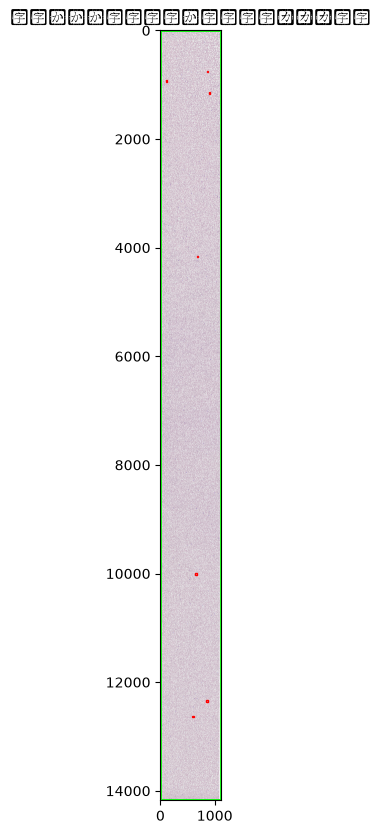

In [4]:
# 組織(細胞)が写っている領域を自動検出し、そこから評価用パッチの座標を決める
## 座標を決め打ちにしない方針:
##   1. WSI全体を安全な低メモリ量で間引き読みし、低解像度オーバービューを作る
##      (get_thumbnail()はlevel_count=1のこのファイルでは全画素デコードが必要になり
##       クラッシュするため使わない)
##   2. 背景(白)でない領域を固定閾値で検出し、組織のバウンディングボックスを
##      level0座標系に変換する
##   3. そのバウンディングボックス内から、実際に組織が写っている座標だけを
##      パッチ位置としてランダムサンプリングする

def build_overview(wsi, downsample=16, strip_height=2000):
    """WSI全体を高さ方向に細切れで読み込み、間引きながら結合した低解像度画像を作る"""
    w, h = wsi.dimensions
    ov_w = max(1, w // downsample)
    rows = []
    for y in range(0, h, strip_height):
        sh = min(strip_height, h - y)
        strip = wsi.read_region((0, y), level=0, size=(w, sh)).convert("RGB")
        strip = strip.resize((ov_w, max(1, sh // downsample)))
        rows.append(np.array(strip))
    return np.vstack(rows)

def find_tissue_bbox(overview, downsample, white_thresh=5):
    """オーバービューから背景(白)でない最大の連結領域を探し、level0座標のbboxを返す"""
    gray = cv2.cvtColor(overview, cv2.COLOR_RGB2GRAY)
    tissue_mask = (gray < (255 - white_thresh)).astype(np.uint8)

    n, labels, stats, _ = cv2.connectedComponentsWithStats(tissue_mask)
    if n <= 1:
        raise ValueError("組織領域が検出できませんでした。white_threshを調整してください。")

    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    x, y, bw, bh, _ = stats[largest]
    return x * downsample, y * downsample, bw * downsample, bh * downsample

def generate_patch_coords(bbox, patch_size, n_patches, wsi_dims, overview, downsample,
                           min_coverage=0.5, white_thresh=5, margin_ratio=0.05, seed=0):
    """bbox内から組織の被覆率がmin_coverage以上の座標だけをパッチ位置として採用する。

    bboxの四隅・端をそのまま使うと、血液塗抹のような細長い組織では
    端(=塗抹の先端や背景)にヒットしやすく白いパッチの原因になるため、
    オーバービュー上の非白画素の割合(被覆率)を候補点ごとに確認してから採用する。
    """
    tx, ty, tw, th = bbox
    w, h = wsi_dims

    gray_ov = cv2.cvtColor(overview, cv2.COLOR_RGB2GRAY)
    tissue_mask_ov = gray_ov < (255 - white_thresh)

    def coverage(x, y):
        ox0, oy0 = int(x / downsample), int(y / downsample)
        ox1 = max(ox0 + 1, int((x + patch_size) / downsample))
        oy1 = max(oy0 + 1, int((y + patch_size) / downsample))
        region = tissue_mask_ov[oy0:oy1, ox0:ox1]
        return region.mean() if region.size else 0.0

    # bboxの端ぎりぎりを避けるため、内側にマージンを取った範囲からサンプリングする
    margin_x, margin_y = tw * margin_ratio, th * margin_ratio
    x_lo, x_hi = tx + margin_x, min(tx + tw, w) - patch_size - margin_x
    y_lo, y_hi = ty + margin_y, min(ty + th, h) - patch_size - margin_y
    if x_hi < x_lo:
        x_lo, x_hi = tx, min(tx + tw, w) - patch_size
    if y_hi < y_lo:
        y_lo, y_hi = ty, min(ty + th, h) - patch_size

    rng = np.random.default_rng(seed)
    coords = []
    max_attempts = n_patches * 300
    for _ in range(max_attempts):
        if len(coords) >= n_patches:
            break
        x = rng.uniform(x_lo, x_hi)
        y = rng.uniform(y_lo, y_hi)
        if coverage(x, y) >= min_coverage:
            coords.append((int(x), int(y)))

    if len(coords) < n_patches:
        raise ValueError(
            f"被覆率{min_coverage}以上の座標が{len(coords)}/{n_patches}件しか見つかりませんでした。"
            "min_coverageを下げるか、n_patchesを減らしてください。"
        )
    return coords

DOWNSAMPLE = 16
overview = build_overview(wsi, downsample=DOWNSAMPLE)
tissue_bbox = find_tissue_bbox(overview, downsample=DOWNSAMPLE)
print("検出された組織領域(level0座標): x=%d, y=%d, w=%d, h=%d" % tissue_bbox)

coords = generate_patch_coords(tissue_bbox, patch_size, n_patches=7, wsi_dims=wsi.dimensions,
                                overview=overview, downsample=DOWNSAMPLE, min_coverage=0.5)
print("自動生成されたパッチ座標:", coords)

# 検出した組織領域とパッチ位置をオーバービュー上に可視化
fig, ax = plt.subplots(figsize=(6, 10))
ax.imshow(overview)
tx, ty, tw, th = tissue_bbox
ax.add_patch(plt.Rectangle((tx / DOWNSAMPLE, ty / DOWNSAMPLE), tw / DOWNSAMPLE, th / DOWNSAMPLE,
                            edgecolor='lime', facecolor='none', linewidth=2))
for (x, y) in coords:
    ax.add_patch(plt.Rectangle((x / DOWNSAMPLE, y / DOWNSAMPLE),
                                patch_size / DOWNSAMPLE, patch_size / DOWNSAMPLE,
                                edgecolor='red', facecolor='none', linewidth=1))
ax.set_title("検出された組織領域と自動生成パッチ位置")
plt.show()

wsi_tests = [wsi.read_region(location=c, level=0, size=(patch_size, patch_size)).convert("RGB") for c in coords]


In [23]:
# 自作関数 pickup_wbc_threshの目的：切り出した塗抹標本画像の中から、白血球（WBC: White Blood Cell）らしき細胞の位置を特定して枠で囲むこと
## 流れ
### 大津の二値化で細胞と背景を分ける
#### size...青み・赤みを平均する四角の1辺。
#### 小さい→青い微小構造(ムラ)にも反応しやすい。偽陽性が増
#### 大きい→局所的な青みが周囲や隣接細胞で薄まり平均値が下がり閾値を超えにくい。偽陰性増。空間分解能が落ち隣接の複数細胞を1つとしたり策の位置・形も粗くなる。
#### sizeは検出したい対象(最小の白血球)の実寸に近い値に寄せるのが理にかなっている
#### size=60...60×60のパネルをずらしながら画像をスキャンする
### 色判定：60×60のパネルの中で，青みが強く赤みが弱い(青が一定以上・赤が一定以下)場所を白血球とみなす(白血球の核は青紫に染まり赤血球は赤く染まる性質)
### 近くにある反応を1つにまとめる：
def pickup_wbc_thresh(wsi_test, size=60, blue_thresh=150, red_thresh=150, size_min=60):
    image_array = np.array(wsi_test) #np.arrayに変換
    print(image_array.shape)
    pil_img = Image.fromarray(image_array) #PIL Image

    # 背景と細胞を分ける
    gray = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY) #gray scale

    ret, binary = cv2.threshold(gray, 10, 255, cv2.THRESH_OTSU + cv2.THRESH_BINARY_INV) #OTSU
    print("OHTSU Thresh :", ret)
    # cv2.threshold…大津の二値化を使って背景を黒，細胞を白にした画像(=binary)を作る

    ## 背景を真っ黒にして，細胞の色だけを残す計算
    # 元のコード…img_pro = np.array([((np.array(image_array[i]).T)*(np.array(binary[i])*np.array([1/255]))).T for i in range(len(image_array))]) #OTSU+color Image
    img_pro = cv2.bitwise_and(image_array, image_array, mask=binary)
    ## 元の画像と背景黒・細胞白の画像(=binary)を掛け合わせて背景を完全に黒くし，細胞の色だけを残す処理をしている

    pil_img = Image.fromarray(img_pro.astype(np.uint8))

    x = 0
    y = 0
    X = [0, 0]
    Y = [0, 0]
    blue_mean_max = 0

    loc_lst = []
    ap = loc_lst.append

    # 60×60の大きさで画像をスキャンして色を判定
    ## for文で縦横10ピクセルずつずらしながらsizeのパッチを切り出す
    for i in range(0, image_array.shape[0], 10):
        for j in range(0, image_array.shape[1], 10):
            pil_img_batch = pil_img.crop((i, j, i+size, j+size))
            numpy_image = np.array(pil_img_batch)
            # OpenCVの色配列は[縦, 横, 色(RGB)]となっている
            blue_mean = numpy_image[:, :, 2].mean() # パッチ内の青色の平均値
            # [:, :, 2]は青色
            red_mean = numpy_image[:, :, 0].mean() # パッチ内の赤色の平均値
            # [:, :, 0]は赤色

            # もし青が強くて，赤が弱ければ白血球とみなす
            if blue_mean > blue_thresh and red_mean < red_thresh:  # 青がblue_threshより高く，赤色がred_threshより低い場所を白血球の候補としてloc_lstに記録
                ap([i, j]) # loc_lstに座標を保存 (ap は loc_lst.append のこと)
            else:
                pass
    area_lst = []
    ap_area = area_lst.append
    del_area = area_lst.remove

    # 見つけた座標を大きな枠にまとめる
    ## 青が強い箇所の座標は，1つの白血球に対して複数箇所検出されているはず
    ## 白血球候補として検出された，近接している座標は1つの大きな四角形(area)に合体させる処理をおkの合う
    for loc in loc_lst:
        for area in area_lst:
            if (area[0][0]-2*size <= loc[0] <= area[0][1]+2*size) and (area[1][0]-2*size <= loc[1] <= area[1][1]+2*size):
            # もし見つけた座標locが既存のareaの近く
            # (locのx座標が既存areaのx範囲を上下に2*sizeした範囲)にあったら…枠の大きさを広げて更新する(合体させる)
                # 枠の大きさを広げて更新する(合体させる)
                xmin = min(loc[0], area[0][0])
                xmax = max(loc[0]+size, area[0][1])
                ymin = min(loc[1], area[1][0])
                ymax = max(loc[1]+size, area[1][1])
                del_area(area) # 古い小さな枠を消す
                ap_area([[xmin, xmax], [ymin, ymax]]) # 大きくなった枠を登録
                break
        else:
            # どの枠の近くにもなければ，新しい独立した枠として登録
            ap_area([[loc[0], loc[0]+size], [loc[1], loc[1]+size]])


    # 緑色の枠を描画して画面に表示
    ## 四角形の4つの角の座標を作り，小さすぎるもの(size/2未満)は除外する
    ## (以前は固定値30でフィルタしていたが、これはsize=60前提の値だったため、
    ##  sizeを変えても自動的に整合するようsize/2に変更)
    pickup_wbc_lst = [[[i[0][0]-size/2, i[1][0]-size/2],
    [i[0][0]-size/2, i[1][1]+size/2],
    [i[0][1]+size/2, i[1][1]+size/2],
    [i[0][1]+size/2, i[1][0]-size/2],
    [i[0][0]-size/2, i[1][0]-size/2]] for i in area_lst if i[0][1]-i[0][0] > size_min and i[1][1]-i[1][0] > size_min]

    wbc_area = np.array(pickup_wbc_lst)
    lc = LineCollection(wbc_area, color='lime', linestyle='dotted')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    # 左側(ax1)に処理前の元画像を表示
    ax1.imshow(image_array) # 元画像を表示
    ax1.set_title("Before: Original")

    # 右側(ax2)に緑枠を重ねた結果を表示
    ax2.imshow(image_array)
    ax2.add_collection(lc) # 元画像の上に枠線を重ねる
    ax2.set_title("After: WBC detection")

    plt.show()


(800, 800, 3)
OHTSU Thresh : 186.0


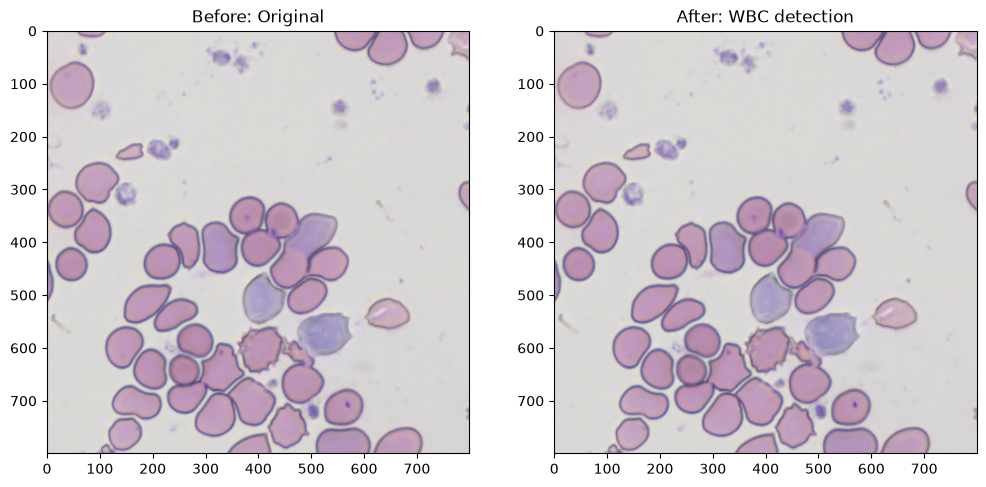

(800, 800, 3)
OHTSU Thresh : 182.0


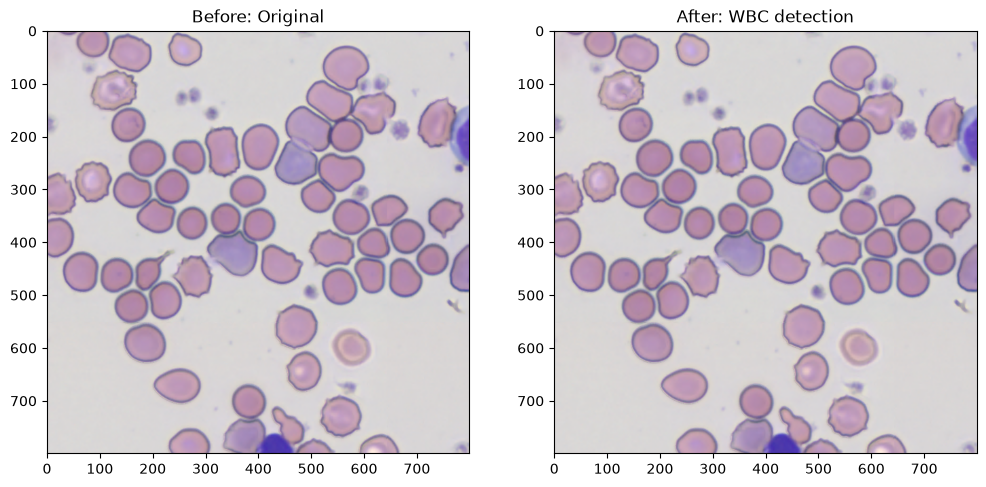

(800, 800, 3)
OHTSU Thresh : 179.0


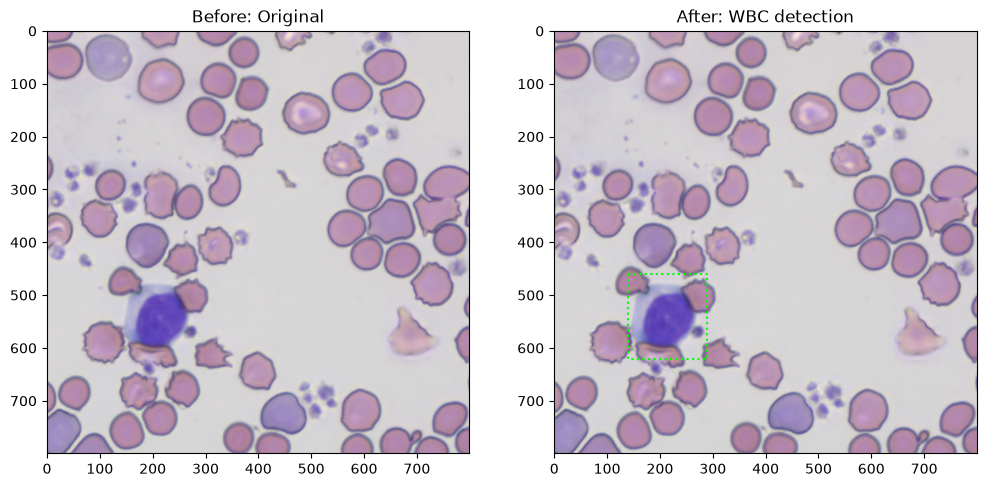

(800, 800, 3)
OHTSU Thresh : 180.0


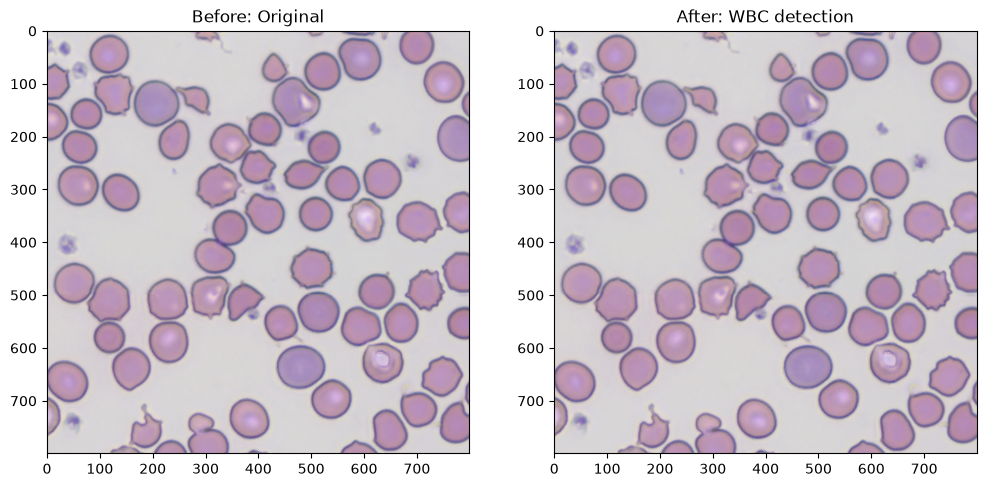

(800, 800, 3)
OHTSU Thresh : 180.0


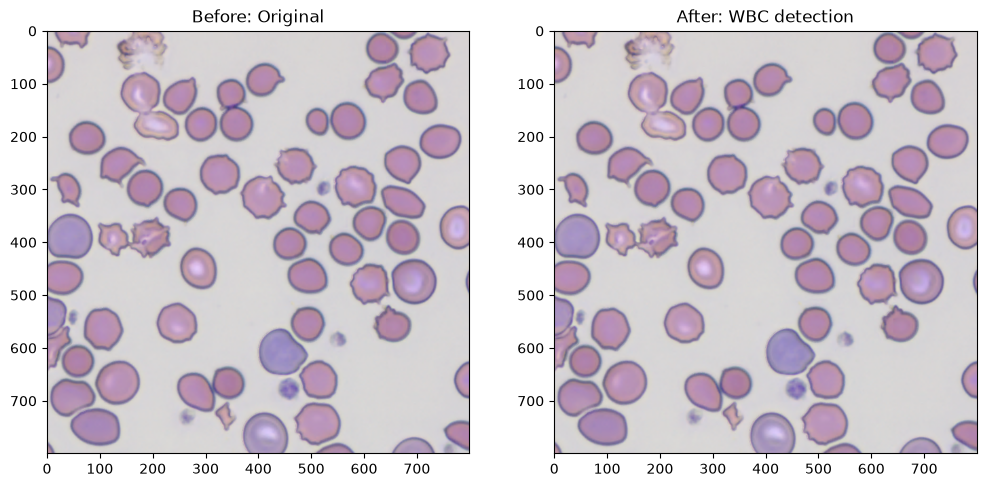

(800, 800, 3)
OHTSU Thresh : 179.0


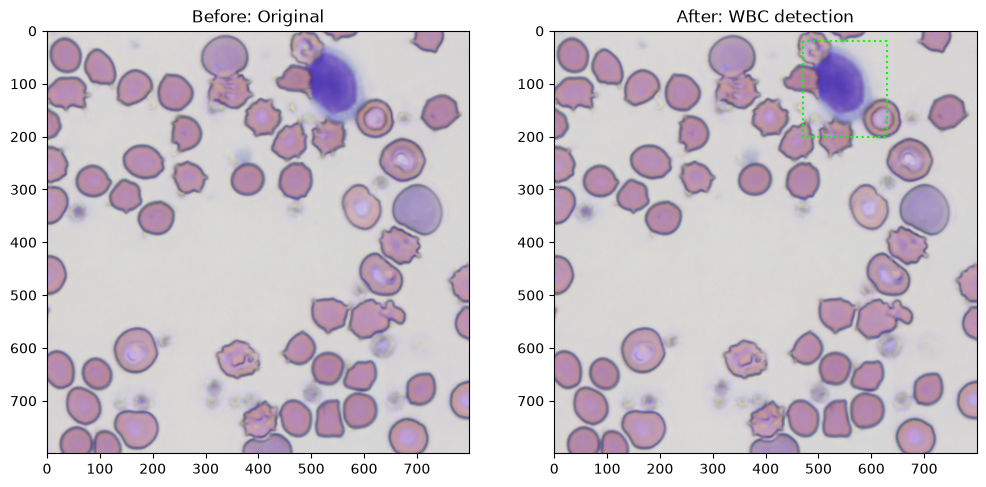

(800, 800, 3)
OHTSU Thresh : 183.0


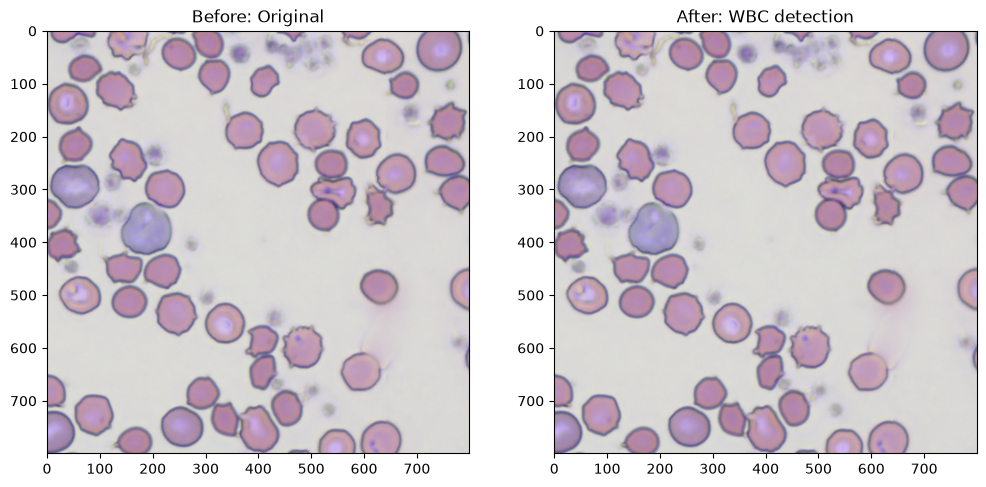

In [26]:
for wsi_test in wsi_tests:
    pickup_wbc_thresh(wsi_test, size=60, blue_thresh=180, red_thresh=130, size_min=60)
# size…検出枠のサイズ(元は60)
# blue_thresh…青さの程度(元は150)

In [ ]:
# なぜsize=10→30に変更,red_thresh=130追加で問題(白血球の一部のみ検出，血小板検出，青い赤血球検出)が減ったのか
# ただしmpp-x=mpp-y≈ 0.0884µm/px→1µm ≈ 11.3px(1/0.0884),
# 血小板23-45px、赤血球68-85px、小型リンパ球68-102px、好中球113-136px、単球136〜204px) の今回の場合。
## size=10→30でマージ許容幅size*2が20→60pxに広がったため.
### 白血球内部の判定は途切れることがあるが，核の半径(68-204px)程度に収まるはず。size=60の時のmerge許容幅はこの範囲だったため
### マージ許容範囲を最小の白血球の直径くらいにするのがいいのかも？一つの白血球内部を認識した複数の枠は白血球の大きさ以内に収まるはずだから。
## size=10→30で局所の青さによる偽陽性が減った。
### size=10だとボックスが小さいため平均値が簡単に上がっていた
### size=10→30で最小サイズフィルタも5→15pxに上がり，血小板を含む孤立した単発の小さい検出が生き残らなくなった
## red_thresh=150→130で赤みの許容範囲が狭まった
### 偽陽性となる青みの強い赤血球は，核を持つ白血球ほど赤みが弱くないため
### 「赤みがもっと弱くないと白血球と認めない」という条件を強くするのが大事
### ただし白血球の中でも細胞質が多く含まれる/好酸性で赤みを帯びる顆粒球などはred_meanが高めのためred_threshを下げすぎると見逃す

# 結論：その画像で1μmが何pxなのかを確かめてからsizeを決める必要がありそう。(そのような式を作る必要がありそう)

In [ ]:
# YOLOの学習データについて
## 必要なデータ数 (Ultralyticsのdocs.ultralytics.comのTips for Best Training Results, Data Collection and Annotation)
## https://docs.ultralytics.com/ja
### クラスあたり最低1500枚程度の画像，クラス辺り10000個以上のBBOXがあると頑健なモデルになりやすい
### 重要なのは枚数ではなくBBOX(白血球)の個数。
### 種類(多様性)の観点で揃えるべきもの:
#### 複数のスライド・複数の個体(個体差の吸収)
#### 同一スライド内でも複数の部位(細胞密度の濃い所・薄い所)
#### 白血球どうしが重なっている/接している難しい例
#### パッチ境界で一部だけ切れている白血球の例
#### 血小板・青みの強い赤血球など、誤検出しやすい「紛らわしいが白血球ではない」領域(ハードネガティブ)を含むパッチ

## データ分割:
### train/val/testの分割は、パッチ単位ではなくスライド(個体)単位で行う。同じスライドのパッチがtrainとvalの両
### 方に入ると、似た画像で検証することになり精度を過大評価してしまう。

### 260403_lps_iwasaka_Image10

In [13]:
path_1 = "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325010260810247.tif"
wsi = OpenSlide(path_1)
# 開いた巨大画像データそのものを格納した変数
patch_size=200*4
# patch_size：切り出す画像の1辺の長さ
## 掛け算にしている理由：基本は200だけど，今回は2倍のサイズで切り出したいという意図など？

In [14]:
# 画像のサイズを知る(横, 縦)
wsi.dimensions

(16010, 226906)

In [15]:
# 手動で領域を乱択
wsi_test1 = wsi.read_region(location=(8000, 10000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test2 = wsi.read_region(location=(8000, 20000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test3 = wsi.read_region(location=(8000, 40000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test4 = wsi.read_region(location=(8000, 60000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test5 = wsi.read_region(location=(8000, 80000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test6 = wsi.read_region(location=(8000, 100000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test7 = wsi.read_region(location=(8000, 120000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_tests = [wsi_test1, wsi_test2, wsi_test3, wsi_test4, wsi_test5, wsi_test6, wsi_test7]

(800, 800, 3)
OHTSU Thresh : 187.0


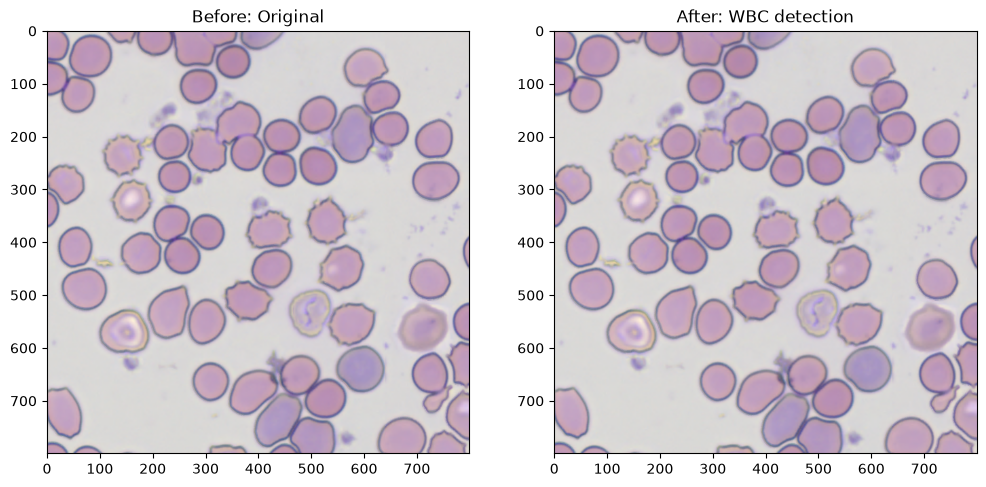

(800, 800, 3)
OHTSU Thresh : 183.0


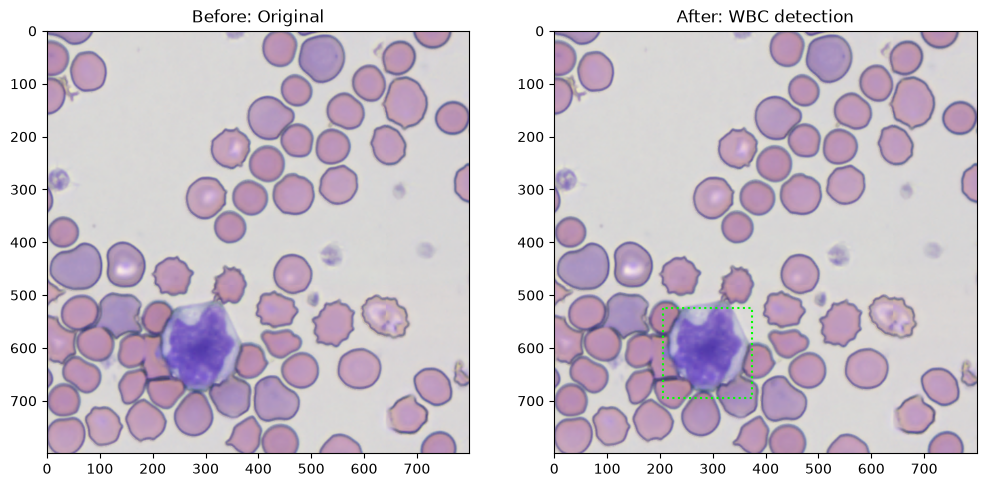

(800, 800, 3)
OHTSU Thresh : 182.0


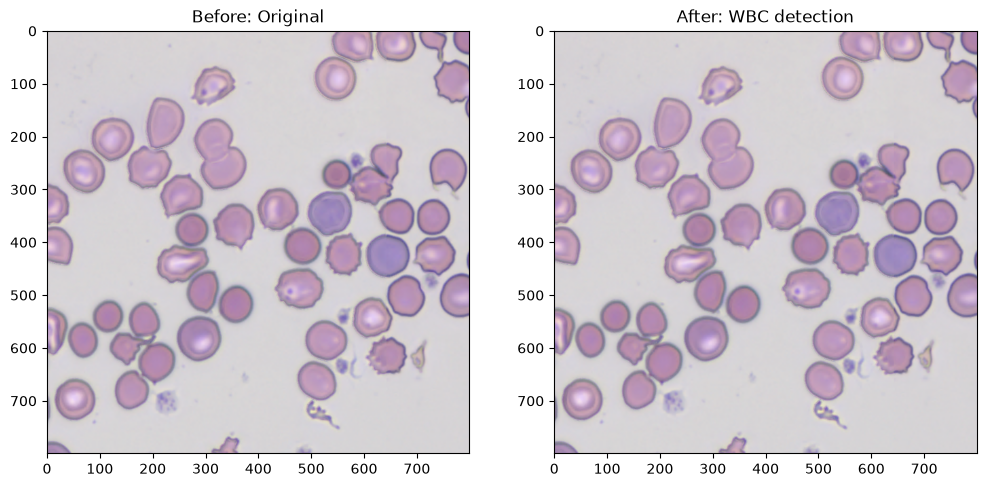

(800, 800, 3)
OHTSU Thresh : 179.0


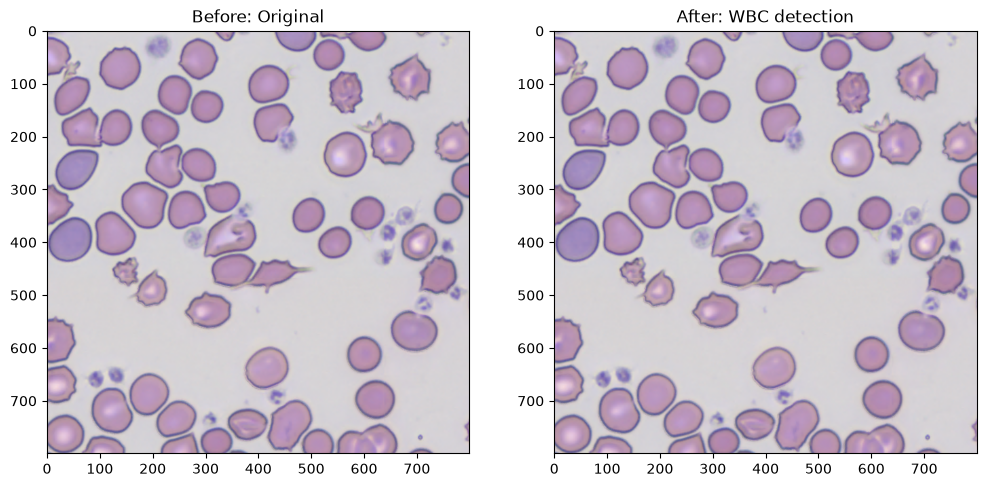

(800, 800, 3)
OHTSU Thresh : 179.0


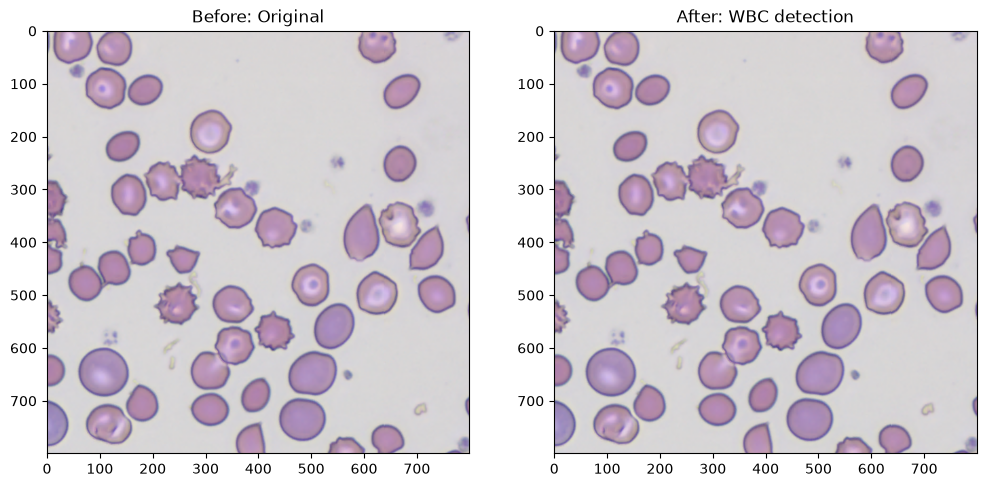

(800, 800, 3)
OHTSU Thresh : 183.0


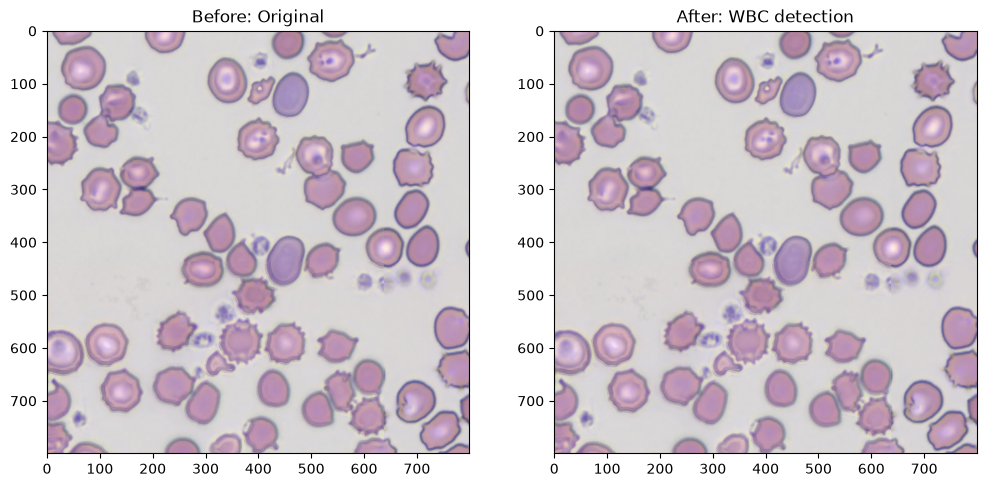

(800, 800, 3)
OHTSU Thresh : 183.0


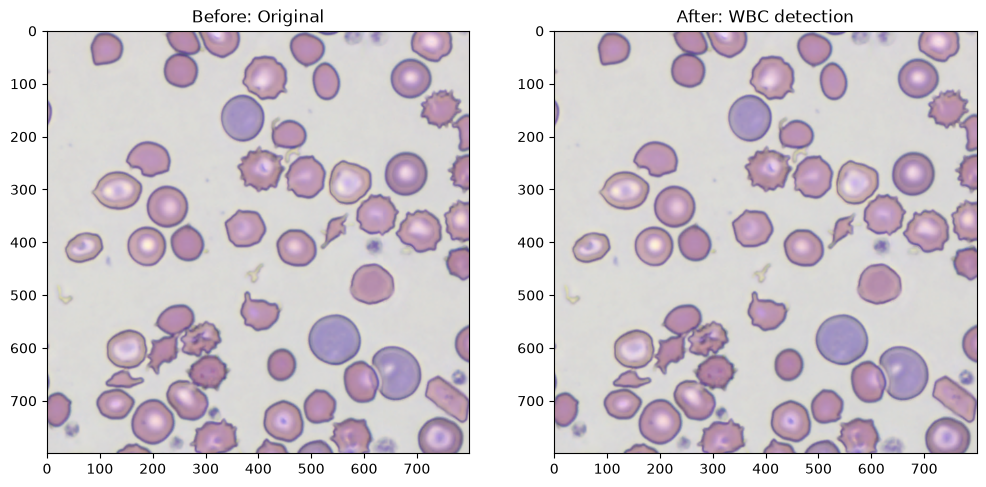

In [16]:
for wsi_test in wsi_tests:
    pickup_wbc_thresh(wsi_test, size=30, blue_thresh=180, red_thresh=130)
# size…検出枠のサイズ(元は60)
# blue_thresh…青さの程度(元は150)

### 260403_lps_iwasaka_Image8

In [ ]:
# 骨髄塗抹
# メイ・ギムザ染色(うちで使っている)
# ライト・ギムザ染色

In [18]:
path_1 = "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325011260810248.tif"
wsi = OpenSlide(path_1)
# 開いた巨大画像データそのものを格納した変数
patch_size=200*4
# patch_size：切り出す画像の1辺の長さ
## 掛け算にしている理由：基本は200だけど，今回は2倍のサイズで切り出したいという意図など？

In [19]:
# 画像のサイズを知る(横, 縦)
wsi.dimensions

(16002, 229058)

In [20]:
# 手動で領域を乱択
wsi_test1 = wsi.read_region(location=(7000, 10000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test2 = wsi.read_region(location=(7000, 20000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test3 = wsi.read_region(location=(7000, 40000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test4 = wsi.read_region(location=(7000, 60000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test5 = wsi.read_region(location=(7000, 80000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test6 = wsi.read_region(location=(7000, 100000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test7 = wsi.read_region(location=(7000, 120000), level=0, size=(patch_size,patch_size)).convert("RGB")

wsi_tests = [wsi_test1, wsi_test2, wsi_test3, wsi_test4, wsi_test5, wsi_test6, wsi_test7]

(800, 800, 3)
OHTSU Thresh : 183.0


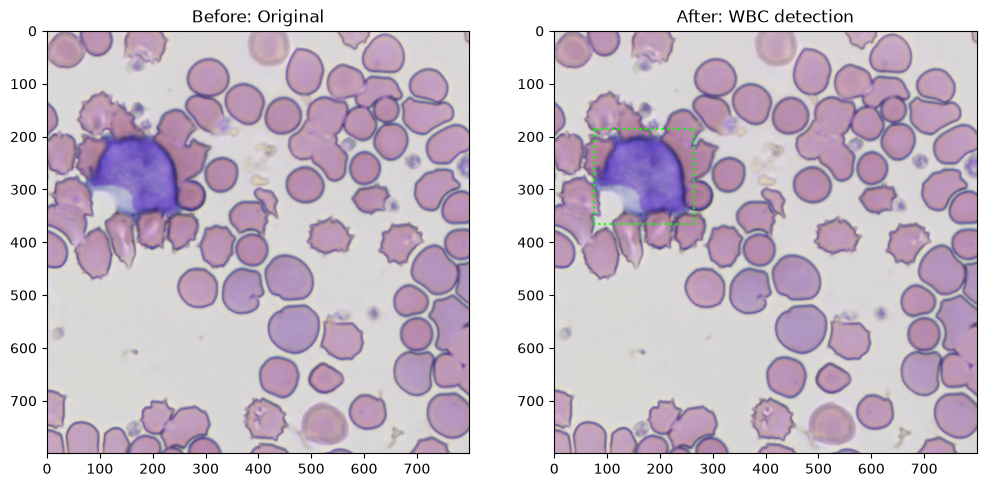

(800, 800, 3)
OHTSU Thresh : 183.0


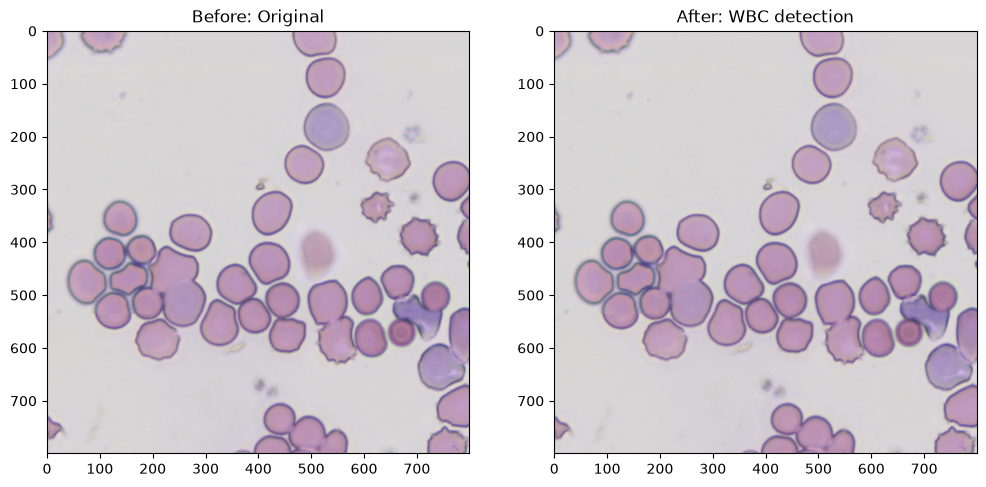

(800, 800, 3)
OHTSU Thresh : 182.0


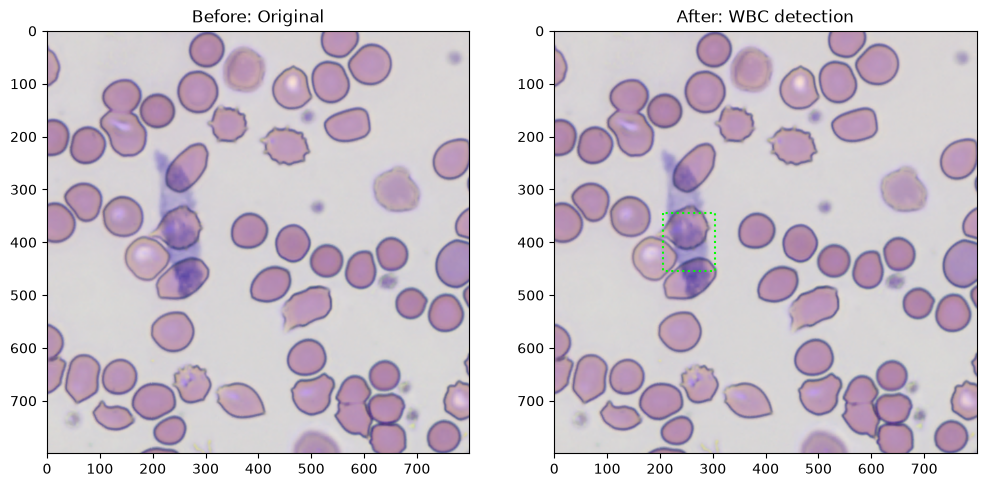

(800, 800, 3)
OHTSU Thresh : 182.0


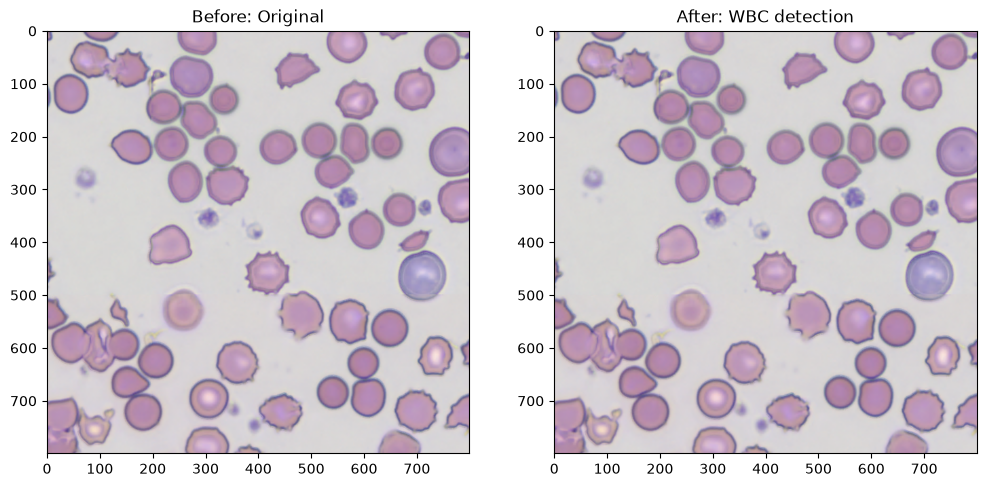

(800, 800, 3)
OHTSU Thresh : 183.0


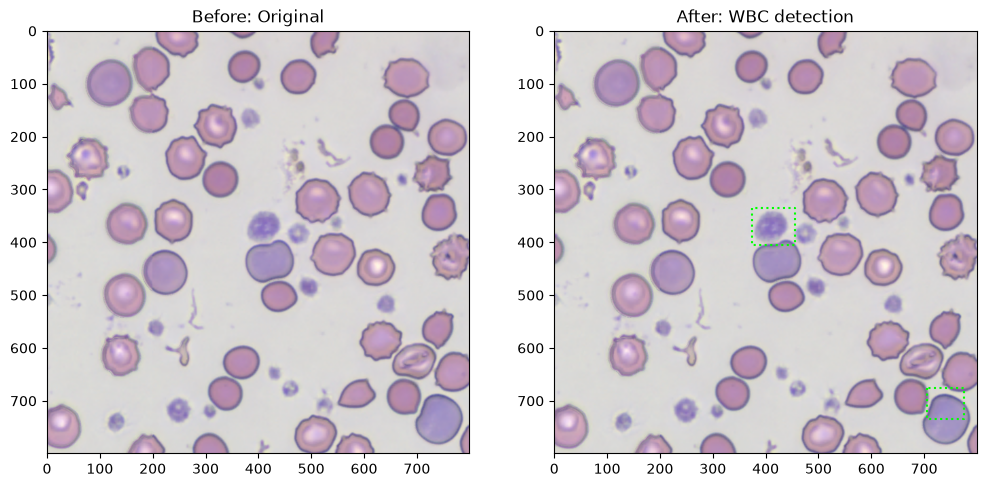

(800, 800, 3)
OHTSU Thresh : 181.0


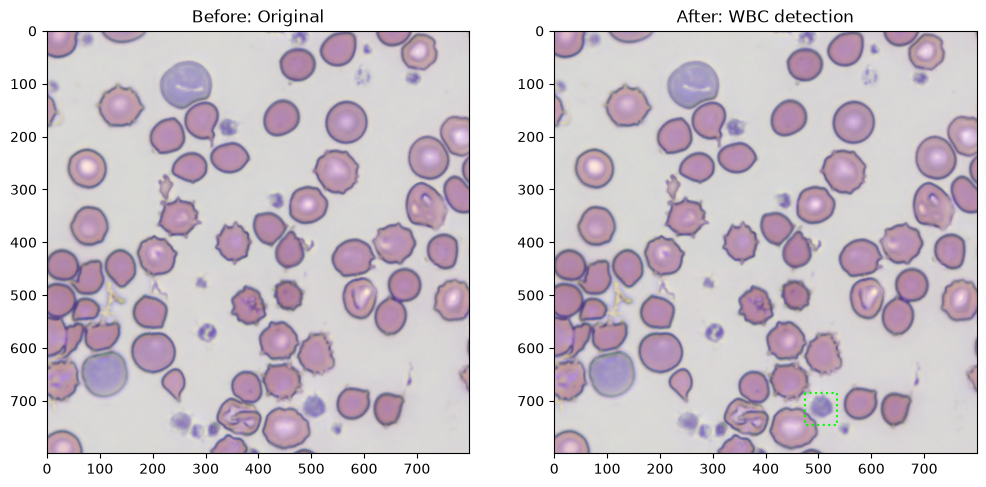

(800, 800, 3)
OHTSU Thresh : 181.0


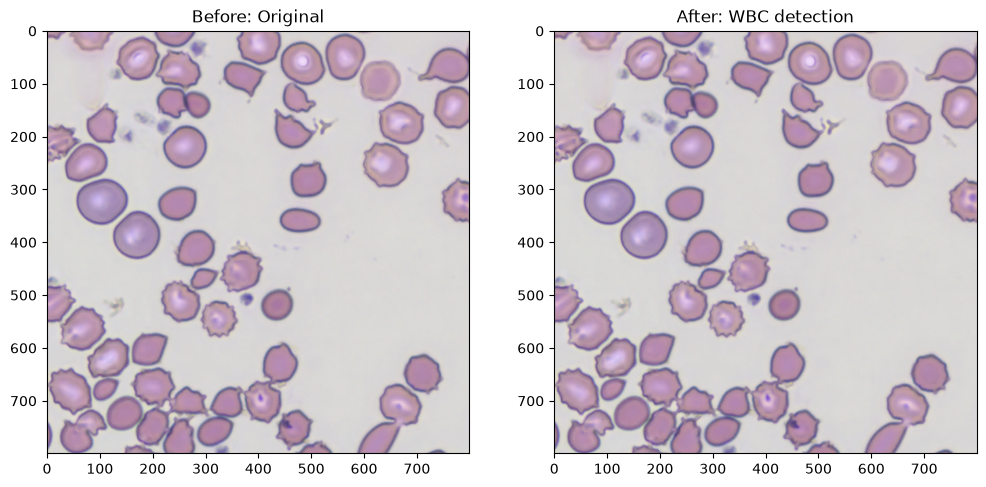

In [22]:
for wsi_test in wsi_tests:
    pickup_wbc_thresh(wsi_test, size=30, blue_thresh=180)
# size…検出枠のサイズ(元は60)
# blue_thresh…青さの程度(元は150)

In [3]:
# 検出器(detect_wbc_boxes)の見逃し(偽陰性)がないかを目視確認するためのセル。
## 1枚のWSIから指定枚数のパッチをランダムに切り出し、検出されたBBoxを緑枠で描画してPNG保存する。
## 検出0件のパッチも(陽性/陰性で選り分けず)そのまま保存するため、
## 「本当は白血球が写っているのに枠が付いていない」パッチがあれば目視で見つけられる。
## ファイル名は {スライド名}_x{X}_y{Y}_n{検出数}.png。_n0.png だけを見れば未検出パッチを優先確認できる。
## 関数はbatch_extract_wbc_patches.pyの同名関数をそのまま貼り付けたもの(import不要にするため)。

from pathlib import Path

import cv2
import numpy as np
from openslide import OpenSlide

# ==== ここを編集する ====
TIF_PATH = "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325009260810246.tif"  # 対象のWSI
OUTPUT_DIR = "/workspace/filesrv02/nakagawa/DigitalHematology/outputs/261030/261030_wbc-patches-check"  # PNGの保存先(無ければ作成)
N_PATCHES = 100      # 切り出すパッチ枚数
PATCH_SIZE = 640     # パッチの1辺(px)。YOLOの入力解像度に合わせている
SIZE = 30            # 色判定する小窓の1辺(px)
BLUE_THRESH = 180    # 青の平均がこれより大きい
RED_THRESH = 130     # 赤の平均がこれより小さい
MIN_BOX_SIZE = 60    # マージ後の枠の縦横がこれ以下なら捨てる(px)
DOWNSAMPLE = 16      # 組織領域検出用プレビューの縮小率
SEED = 0             # 乱数シード(変えると別の座標が選ばれる)
# =======================


# ---------------------------------------------------------------------------
# 1. 組織領域の検出とパッチ候補座標のサンプリング
# ---------------------------------------------------------------------------

# WSI全体の縮小プレビューを作る
def build_overview(wsi, downsample=16, strip_height=2000):
    """WSI全体を高さ方向に細切れで読み込み、間引きながら結合した低解像度画像を作る"""
    w, h = wsi.dimensions
    ov_w = max(1, w // downsample)
    rows = []
    for y in range(0, h, strip_height):
        sh = min(strip_height, h - y)
        strip = wsi.read_region((0, y), level=0, size=(w, sh)).convert("RGB")
        strip = strip.resize((ov_w, max(1, sh // downsample)))
        rows.append(np.array(strip))
    return np.vstack(rows)


# プレビューから組織の範囲を見つける
def find_tissue_bbox(overview, downsample, white_thresh=5):
    """オーバービューから背景(白)でない最大の連結領域を探し、level0座標のbboxを返す"""
    gray = cv2.cvtColor(overview, cv2.COLOR_RGB2GRAY)
    tissue_mask = (gray < (255 - white_thresh)).astype(np.uint8)

    n, labels, stats, _ = cv2.connectedComponentsWithStats(tissue_mask)
    if n <= 1:
        raise ValueError("組織領域が検出できませんでした。white_threshを調整してください。")

    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    x, y, bw, bh, _ = stats[largest]
    return x * downsample, y * downsample, bw * downsample, bh * downsample


# パッチ候補座標をランダムに作る
def generate_candidate_coords(bbox, patch_size, n_candidates, wsi_dims, overview, downsample,
                               min_coverage=0.5, white_thresh=5, margin_ratio=0.05, seed=0):
    """組織の被覆率がmin_coverage以上の候補座標をn_candidates件作る(重複除去なし)。"""
    tx, ty, tw, th = bbox
    w, h = wsi_dims

    gray_ov = cv2.cvtColor(overview, cv2.COLOR_RGB2GRAY)
    tissue_mask_ov = gray_ov < (255 - white_thresh)

    def coverage(x, y):
        ox0, oy0 = int(x / downsample), int(y / downsample)
        ox1 = max(ox0 + 1, int((x + patch_size) / downsample))
        oy1 = max(oy0 + 1, int((y + patch_size) / downsample))
        region = tissue_mask_ov[oy0:oy1, ox0:ox1]
        return region.mean() if region.size else 0.0

    margin_x, margin_y = tw * margin_ratio, th * margin_ratio
    x_lo, x_hi = tx + margin_x, min(tx + tw, w) - patch_size - margin_x
    y_lo, y_hi = ty + margin_y, min(ty + th, h) - patch_size - margin_y
    if x_hi < x_lo:
        x_lo, x_hi = tx, min(tx + tw, w) - patch_size
    if y_hi < y_lo:
        y_lo, y_hi = ty, min(ty + th, h) - patch_size

    rng = np.random.default_rng(seed)
    coords = []
    max_attempts = n_candidates * 300
    for _ in range(max_attempts):
        if len(coords) >= n_candidates:
            break
        x = rng.uniform(x_lo, x_hi)
        y = rng.uniform(y_lo, y_hi)
        if coverage(x, y) >= min_coverage:
            coords.append((int(x), int(y)))
    return coords


# ---------------------------------------------------------------------------
# 2. 白血球候補の検出(cell-9のpickup_wbc_threshから可視化部分を除き、BBoxを返すように整理したもの)
# ---------------------------------------------------------------------------

def detect_wbc_boxes(image_array, size=30, blue_thresh=180, red_thresh=130, step=10, min_box_size=60):
    """画像配列(H, W, 3)を受け取り、白血球候補のBBox [(x_min, y_min, x_max, y_max), ...] を返す。"""
    gray = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY)
    _, binary = cv2.threshold(gray, 10, 255, cv2.THRESH_OTSU + cv2.THRESH_BINARY_INV)
    img_pro = cv2.bitwise_and(image_array, image_array, mask=binary)

    h, w = image_array.shape[:2]
    hits = []
    for row in range(0, h, step):
        for col in range(0, w, step):
            patch = img_pro[row:row + size, col:col + size]
            if patch.size == 0:
                continue
            blue_mean = patch[:, :, 2].mean()
            red_mean = patch[:, :, 0].mean()
            if blue_mean > blue_thresh and red_mean < red_thresh:
                hits.append((row, col))

    # 近接するヒットを1つの矩形にまとめる(元のarea_lstマージロジックを踏襲)
    regions = []  # [row_min, row_max, col_min, col_max]
    merge_margin = 2 * size
    for row, col in hits:
        merged = False
        for idx, (rmin, rmax, cmin, cmax) in enumerate(regions):
            if (rmin - merge_margin <= row <= rmax + merge_margin) and \
               (cmin - merge_margin <= col <= cmax + merge_margin):
                regions[idx] = [min(rmin, row), max(rmax, row + size),
                                 min(cmin, col), max(cmax, col + size)]
                merged = True
                break
        if not merged:
            regions.append([row, row + size, col, col + size])

    boxes = []
    for rmin, rmax, cmin, cmax in regions:
        if (rmax - rmin) > min_box_size and (cmax - cmin) > min_box_size:
            x_min = max(0, cmin - size / 2)
            x_max = min(w, cmax + size / 2)
            y_min = max(0, rmin - size / 2)
            y_max = min(h, rmax + size / 2)
            boxes.append((x_min, y_min, x_max, y_max))
    return boxes


# ---------------------------------------------------------------------------
# 3. 描画と保存
# ---------------------------------------------------------------------------

def draw_boxes(image_array, boxes, color=(0, 255, 0), thickness=2):
    """検出されたBBoxを緑枠で描画したコピーを返す(元のimage_arrayは変更しない)"""
    drawn = image_array.copy()
    for x_min, y_min, x_max, y_max in boxes:
        cv2.rectangle(drawn, (int(x_min), int(y_min)), (int(x_max), int(y_max)), color, thickness)
    return drawn


def inspect_wbc_detection(tif_path, output_dir):
    # 処理を関数にまとめ、上のセルのwsi/coords/overviewなどの変数を上書きしないようにしている
    tif_path = Path(tif_path)
    if not tif_path.is_file():
        raise FileNotFoundError(f"TIF_PATHが見つかりません: {tif_path}")
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    wsi = OpenSlide(str(tif_path))
    slide_name = tif_path.stem

    # build_overviewはWSI全体を間引き読みするため数分かかることがある
    overview = build_overview(wsi, downsample=DOWNSAMPLE)
    bbox = find_tissue_bbox(overview, downsample=DOWNSAMPLE)

    coords = generate_candidate_coords(
        bbox, PATCH_SIZE, n_candidates=N_PATCHES, wsi_dims=wsi.dimensions,
        overview=overview, downsample=DOWNSAMPLE, seed=SEED,
    )
    if len(coords) < N_PATCHES:
        print(f"警告: 要求{N_PATCHES}枚に対し{len(coords)}枚しか座標が得られませんでした")

    n_with_detection = 0
    for x, y in coords:
        patch_img = wsi.read_region((x, y), level=0, size=(PATCH_SIZE, PATCH_SIZE)).convert("RGB")
        image_array = np.array(patch_img)

        boxes = detect_wbc_boxes(
            image_array, size=SIZE, blue_thresh=BLUE_THRESH,
            red_thresh=RED_THRESH, min_box_size=MIN_BOX_SIZE,
        )
        if boxes:
            n_with_detection += 1

        drawn = draw_boxes(image_array, boxes)
        # ファイル名に検出数nを入れておくと、n0(未検出)だけを後で一覧表示して
        # 見逃しが無いか優先的にチェックできる
        patch_id = f"{slide_name}_x{x}_y{y}_n{len(boxes)}"
        cv2.imwrite(str(output_dir / f"{patch_id}.png"), cv2.cvtColor(drawn, cv2.COLOR_RGB2BGR))

    wsi.close()
    print(f"完了: {len(coords)}枚中{n_with_detection}枚で検出あり。出力先: {output_dir}")


inspect_wbc_detection(TIF_PATH, OUTPUT_DIR)

完了: 100枚中4枚で検出あり。出力先: /workspace/filesrv02/nakagawa/DigitalHematology/outputs/261030/261030_wbc-patches-check


In [ ]:
# 検出された4枚
## /workspace/filesrv02/nakagawa/DigitalHematology/outputs/261030/261030_wbc-patches-check/s260325009260810246_x888_y168677_n1.png
## /workspace/filesrv02/nakagawa/DigitalHematology/outputs/261030/261030_wbc-patches-check/s260325009260810246_x8865_y124174_n1.png
## /workspace/filesrv02/nakagawa/DigitalHematology/outputs/261030/261030_wbc-patches-check/s260325009260810246_x13786_y37171_n1.png
## /workspace/filesrv02/nakagawa/DigitalHematology/outputs/261030/261030_wbc-patches-check/s260325009260810246_x13996_y86567_n1.png

# 偽陽性・偽陰性…なし

# 見切れていた白血球：検出されず
## /workspace/filesrv02/nakagawa/DigitalHematology/outputs/261030/261030_wbc-patches-check/s260325009260810246_x1363_y14713_n0.png